JS01 Praktikum 1 - Instalasi Perangkat (transposisi jadi script verifikasi).

Modul aslinya berisi langkah klik-klik di Google Colab dan instalasi Anaconda/vscode.
Yang bisa dijalankan otomatis adalah VERIFIKASI hasil instalasi: versi python,
library, backend matplotlib, dan uji asap (smoke test) model sederhana.
Output: output/versi_library.csv, output/01_smoke_test.png

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("instalasi_dan_verifikasi.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js01-pengenalan-pembelajaran-mesin\praktikum-1


In [2]:
import os
import platform
import sys
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.datasets import load_iris
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

print("=" * 62)
print("JS01 / Praktikum 1 - Verifikasi Instalasi Perangkat")
print("=" * 62)
print(f"python        : {sys.version.split()[0]}")
print(f"executable    : {sys.executable}")
print(f"platform      : {platform.platform()}")
print(f"cpu count     : {os.cpu_count()}")
print(f"venv aktif    : {os.environ.get('VIRTUAL_ENV', '(tidak terdeteksi dari env)')}")

JS01 / Praktikum 1 - Verifikasi Instalasi Perangkat
python        : 3.10.6
executable    : C:\code\pemmes26\.venv\Scripts\python.exe
platform      : Windows-10-10.0.26200-SP0
cpu count     : 8
venv aktif    : (tidak terdeteksi dari env)


In [3]:
# --- 1. Cek library yang dipakai sepanjang praktikum -------------------------
libs = [
    ("numpy", "komputasi array/matriks"),
    ("pandas", "tabel data (DataFrame)"),
    ("matplotlib", "visualisasi"),
    ("seaborn", "visualisasi statistik"),
    ("scipy", "komputasi ilmiah"),
    ("sklearn", "algoritma pembelajaran mesin"),
    ("statsmodels", "statistika inferensial"),
    ("skimage", "pengolahan citra"),
    ("cv2", "computer vision (OpenCV)"),
    ("nltk", "pengolahan bahasa alami"),
]

print("\n[1] Library wajib")
print(f"{'paket':<14}{'versi':<12}{'status':<10}kegunaan")
print("-" * 62)
rows = []
for mod_name, kegunaan in libs:
    try:
        mod = __import__(mod_name)
        ver = getattr(mod, "__version__", "?")
        status = "OK"
    except Exception as exc:  # noqa: BLE001 - laporan audit
        ver, status = "-", f"GAGAL ({type(exc).__name__})"
    rows.append((mod_name, ver, status, kegunaan))
    print(f"{mod_name:<14}{ver:<12}{status:<10}{kegunaan}")

gagal = [r for r in rows if r[2] != "OK"]
print(f"\nlibrary OK: {len(rows) - len(gagal)}/{len(rows)}")


[1] Library wajib
paket         versi       status    kegunaan
--------------------------------------------------------------
numpy         2.2.6       OK        komputasi array/matriks
pandas        2.3.3       OK        tabel data (DataFrame)
matplotlib    3.10.9      OK        visualisasi


seaborn       0.13.2      OK        visualisasi statistik
scipy         1.15.3      OK        komputasi ilmiah
sklearn       1.7.2       OK        algoritma pembelajaran mesin
statsmodels   0.15.0      OK        statistika inferensial
skimage       0.25.2      OK        pengolahan citra


cv2           5.0.0       OK        computer vision (OpenCV)


nltk          3.10.3      OK        pengolahan bahasa alami

library OK: 10/10


In [4]:
# --- 2. Uji asap: satu model klasifikasi kecil harus jalan -------------------
print("\n[2] Uji asap model (DecisionTree pada Iris)")
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=RANDOM_STATE, stratify=iris.target
)
clf = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
acc = accuracy_score(y_test, pred)
print(f"data latih/uji : {X_train.shape[0]}/{X_test.shape[0]}")
print(f"akurasi uji    : {acc:.4f}")


[2] Uji asap model (DecisionTree pada Iris)
data latih/uji : 105/45
akurasi uji    : 0.9778



tabel versi -> versi_library.csv


grafik       -> 01_smoke_test.png


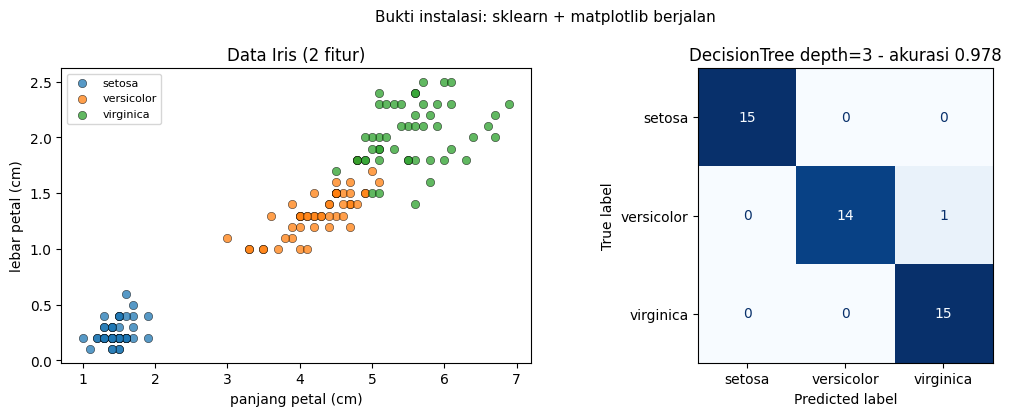

In [5]:
# --- 3. Simpan tabel versi + grafik bukti ------------------------------------
import csv

csv_path = OUT / "versi_library.csv"
with csv_path.open("w", newline="", encoding="utf-8") as fh:
    wr = csv.writer(fh)
    wr.writerow(["paket", "versi", "status", "kegunaan"])
    wr.writerows(rows)
print(f"\ntabel versi -> {csv_path.name}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for k, nama in enumerate(iris.target_names):
    ax.scatter(
        iris.data[iris.target == k, 2], iris.data[iris.target == k, 3],
        label=nama, alpha=0.75, edgecolor="k", linewidth=0.4,
    )
ax.set_xlabel("panjang petal (cm)")
ax.set_ylabel("lebar petal (cm)")
ax.set_title("Data Iris (2 fitur)")
ax.legend(fontsize=8)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names, ax=axes[1], colorbar=False, cmap="Blues"
)
axes[1].set_title(f"DecisionTree depth=3 - akurasi {acc:.3f}")
fig.suptitle("Bukti instalasi: sklearn + matplotlib berjalan", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "01_smoke_test.png", dpi=130)
print(f"grafik       -> {(OUT / '01_smoke_test.png').name}")

In [6]:
# --- 4. Catatan padanan Colab vs lokal --------------------------------------
print("\n[3] Padanan perintah Colab vs lokal (Windows)")
padanan = [
    ("!pip install mne", "pip install mne"),
    ("!ls /content", "dir"),
    ("!nvidia-smi", "nvidia-smi"),
    ("runtime GPU (menu)", "pasang CUDA toolkit manual"),
]
for colab, lokal in padanan:
    print(f"  {colab:<24}-> {lokal}")

assert not gagal, f"library wajib belum lengkap: {gagal}"
assert acc > 0.85, f"akurasi uji asap terlalu rendah: {acc:.3f}"
assert (OUT / "01_smoke_test.png").stat().st_size > 10_000
print("\nSELESAI: instalasi terverifikasi, semua library wajib tersedia.")


[3] Padanan perintah Colab vs lokal (Windows)
  !pip install mne        -> pip install mne
  !ls /content            -> dir
  !nvidia-smi             -> nvidia-smi
  runtime GPU (menu)      -> pasang CUDA toolkit manual

SELESAI: instalasi terverifikasi, semua library wajib tersedia.
